# Análisis de Datos - Fase 3

In [1]:
import warnings
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize, stats
from IPython.display import display

# Dont print warnings
warnings.simplefilter(action="ignore")

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)

## Datos crudos

Se cargan sin modificar; todas las demás tablas se derivan de estas dos.

- `raw_phase1`: formulario de perfil de la Fase 1, una fila por participante.
- `raw_phase3`: exportación de la encuesta de la Fase 3 en formato largo, una fila por respuesta (en
  las preguntas Likert, una fila por ítem). `section` es la parte de la encuesta (`background`,
  `tasks`, `feedback`), `step` la herramienta (`nix`, `nixty`), `is_correct` si la respuesta es
  correcta y `time_ms` el tiempo en pantalla en milisegundos.

In [2]:
# Loading Data
DATA = Path("data")

# Fase 1: profile form, one row per participant
raw_phase1 = pd.read_csv(DATA / "phase1" / "demographics.csv", index_col=0)
raw_phase1.index.name = "Participante"

# Fase 3: survey export in long format (one row per answer, likert: one row per item).
# The newest export in the folder is used.
phase3_file = sorted(glob.glob(str(DATA / "phase3" / "nixty-survey-answers-*.csv")))[-1]
raw_phase3 = pd.read_csv(phase3_file)

print(f"Fase 1: {len(raw_phase1)} participantes")
print(f"Fase 3: {phase3_file}, {len(raw_phase3)} filas, {raw_phase3['username'].nunique()} participantes")
raw_phase1

Fase 1: 10 participantes
Fase 3: data/phase3/nixty-survey-answers-2026-10-22.csv, 1960 filas, 20 participantes


,Edad,Semestre,Tienes experiencia con manejadores de paquetes,Has empaquetado,Lenguajes
Participante,,,,,
P01,22,10,Si,No,Python
P02,23,10,Si,Si,Python
P03,22,10,Si,No,"Java,Javascript,Python"
P04,23,10,Si,Si,"Bash,C,Javascript,Python"
P05,22,10,Si,Si,"Javascript,Typescript,Python"
P06,23,10,Si,No,Python
P07,23,10,Si,No,"Java,Javascript,Typescript,Python"
P08,22,10,Si,Si,"Bash,Java,Javascript,Typescript,Python"
P09,21,10,Si,Si,NaN


In [3]:
raw_phase3.head(10)

,username,survey_order,step,step_position,section,question_id,kind,item_id,option_id,value,is_correct,answered_at,time_ms
0,P08,"nix,nixty",background,NaN,background,background.experience,likert,package-management,NaN,5,NaN,2026-10-18T01:35:45Z,20012
1,P08,"nix,nixty",background,NaN,background,background.experience,likert,typescript,NaN,4,NaN,2026-10-18T01:35:45Z,20012
2,P08,"nix,nixty",background,NaN,background,background.experience,likert,nixlang,NaN,1,NaN,2026-10-18T01:35:45Z,20012
3,P08,"nix,nixty",background,NaN,background,background.experience,likert,functional,NaN,4,NaN,2026-10-18T01:35:45Z,20012
4,P08,"nix,nixty",nix,1.0,tasks,nix.instructions,info,NaN,NaN,NaN,NaN,2026-10-18T01:36:05Z,15279
5,P08,"nix,nixty",nix,1.0,tasks,nix.PA1-1,choice_code,NaN,b,NaN,False,2026-10-18T01:39:39Z,213511
6,P08,"nix,nixty",nix,1.0,tasks,nix.PA1-2,choice_code,NaN,c,NaN,False,2026-10-18T01:40:13Z,34096
7,P08,"nix,nixty",nix,1.0,tasks,nix.PA2-1,choice_code,NaN,b,NaN,False,2026-10-18T01:41:05Z,51527
8,P08,"nix,nixty",nix,1.0,tasks,nix.PA2-2,choice_code,NaN,NaN,NaN,NaN,2026-10-18T01:41:07Z,2050
9,P08,"nix,nixty",nix,1.0,tasks,nix.PA3-1,choice_code,NaN,a,NaN,True,2026-10-18T01:45:46Z,279054


### Definiciones del método

Preguntas $P_1 \dots P_{11}$ del método de Mernik et al. y el id del cuestionario que mide cada una.
$P_1$–$P_8$ tienen una variante fácil (`-1`) y una difícil y opcional (`-2`); $P_9$–$P_{11}$ son los
ejercicios de programación libre. La matriz $Q_{ij}$ está transcrita de `thesis.typ` (@cuadro1), y es
la misma que la Tabla 5 del artículo.

En la matriz, 1 indica que la dimensión $i$ (fila) se relaciona con la pregunta $j$ (columna) y 0 que
no. $C_j$, la suma de cada columna, es el número de dimensiones relacionadas con la pregunta $j$, y
$Q_{ij} / C_j$ (`weights`) es el peso de la pregunta $j$ en la dimensión $i$.

In [4]:
TOOLS = {"nix": "Nixlang", "nixty": "Nixty"}
TOOL_ORDER = list(TOOLS.values())
DIFF = "Nixty − Nixlang"

questions = pd.DataFrame(
    [
        ("P1", "PA1", "Aprendizaje", "Seleccionar declaraciones sintácticamente correctas"),
        ("P2", "PA2", "Aprendizaje", "Seleccionar declaraciones sin sentido"),
        ("P3", "PA3", "Aprendizaje", "Seleccionar un programa válido para un resultado dado"),
        ("P4", "PP4", "Percepción", "Seleccionar el resultado correcto de un programa"),
        ("P5", "PP5", "Percepción", "Identificar constructos del lenguaje"),
        ("P6", "PP6", "Percepción", "Seleccionar un programa con el mismo resultado"),
        ("P7", "PP7", "Percepción", "Seleccionar el significado correcto de un constructo nuevo"),
        ("P8", "PP8", "Percepción", "Identificar constructos en un programa con comentarios"),
        ("P9", "PE9", "Evolución", "Expandir el programa con nueva funcionalidad"),
        ("P10", "PE10", "Evolución", "Eliminar funcionalidad del programa"),
        ("P11", "PE11", "Evolución", "Cambiar funcionalidad del programa"),
    ],
    columns=["Pregunta", "id", "Categoría", "Descripción"],
).set_index("Pregunta")

# Q_ij: 1 when dimension i is related to question j
cd_matrix = pd.DataFrame.from_dict(
    {
        "Cercanía de mapeo":              [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        "Viscosidad":                     [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1],
        "Dependencias ocultas":           [0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0],
        "Operaciones mentales difíciles": [0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
        "Anticipación impuesta":          [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1],
        "Notación secundaria":            [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
        "Visibilidad":                    [0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0],
        "Consistencia":                   [0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
        "Difusión":                       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        "Propensión a errores":           [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        "Evaluación progresiva":          [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        "Expresividad de rol":            [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        "Gradiente de abstracción":       [0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    },
    orient="index",
    columns=questions.index,
)
cd_matrix.index.name = "Dimensión"

# C_j: number of dimensions related to question j; weights: Q_ij / C_j
C = cd_matrix.sum()
weights = cd_matrix.div(C, axis=1)

display(questions)
cd_matrix

,id,Categoría,Descripción
Pregunta,,,
P1,PA1,Aprendizaje,Seleccionar declaraciones sintácticamente corr...
P2,PA2,Aprendizaje,Seleccionar declaraciones sin sentido
P3,PA3,Aprendizaje,Seleccionar un programa válido para un resulta...
P4,PP4,Percepción,Seleccionar el resultado correcto de un programa
P5,PP5,Percepción,Identificar constructos del lenguaje
P6,PP6,Percepción,Seleccionar un programa con el mismo resultado
P7,PP7,Percepción,Seleccionar el significado correcto de un cons...
P8,PP8,Percepción,Identificar constructos en un programa con com...
P9,PE9,Evolución,Expandir el programa con nueva funcionalidad


Pregunta,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,P11
Dimensión,,,,,,,,,,,
Cercanía de mapeo,1,1,1,1,1,1,1,1,1,1,1
Viscosidad,0,0,0,0,0,0,0,0,1,1,1
Dependencias ocultas,0,0,1,1,1,1,0,1,0,1,0
Operaciones mentales difíciles,0,1,1,1,1,1,1,1,0,0,0
Anticipación impuesta,0,0,0,0,0,0,0,0,1,0,1
Notación secundaria,0,0,0,0,0,0,0,1,0,0,0
Visibilidad,0,0,1,1,1,1,1,1,0,0,0
Consistencia,0,0,0,0,0,1,1,0,0,0,0
Difusión,1,1,1,1,1,1,1,1,1,1,1


Ítems de la encuesta de satisfacción (`annex/4/survey_*_phase3.typ`), en el orden en que se
mostraron. Los pares de palabras son un solo bloque: primero los 10 de Short AttrakDiff 2 (SAD-2) y
después los 12 de DEXI. `Par` está escrito como *negativo – positivo*; `Invertido` marca los ítems
cuyo polo positivo estaba a la izquierda (valor 1).

`Instrumento` es el cuestionario de origen y `Calidad` el grupo al que pertenece el ítem (General,
Pragmática o Hedónica), como en Kuusinen.

In [5]:
ux_items = pd.DataFrame(
    [
        ("experience", "OUX", "Global", "Malo – Bueno", True),
        ("needs", "NFS", "Global", "Para nada – Completamente", False),
        ("malo-bueno", "SAD-2", "General", "Malo – Bueno", False),
        ("feo-bonito", "SAD-2", "General", "Feo – Bonito", False),
        ("confuso-estructurado", "SAD-2", "Pragmática", "Confuso – Estructurado", False),
        ("practico", "SAD-2", "Pragmática", "Impráctico – Práctico", True),
        ("impredecible-predecible", "SAD-2", "Pragmática", "Impredecible – Predecible", False),
        ("simple-complicado", "SAD-2", "Pragmática", "Complicado – Simple", True),
        ("antipatico-cautivador", "SAD-2", "Hedónica", "Antipático – Cautivador", False),
        ("elegante-tosco", "SAD-2", "Hedónica", "Tosco – Elegante", True),
        ("barato-premium", "SAD-2", "Hedónica", "Barato – Prémium", False),
        ("creativo", "SAD-2", "Hedónica", "No imaginativo – Creativo", True),
        ("recomendable", "DEXI", "General", "No recomendable – Recomendable", True),
        ("eficiente", "DEXI", "Pragmática", "Ineficiente – Eficiente", True),
        ("flexible-rigido", "DEXI", "Pragmática", "Rígido – Flexible", True),
        ("facil-aprender", "DEXI", "Pragmática", "Difícil de aprender – Fácil de aprender", True),
        ("limitado-extensivo", "DEXI", "Pragmática", "Limitado – Extensivo", False),
        ("desinformativo-informativo", "DEXI", "Pragmática", "Desinformativo – Informativo", False),
        ("motivador", "DEXI", "Hedónica", "Desmotivador – Motivador", True),
        ("respeto-desconfianza", "DEXI", "Hedónica", "Genera desconfianza – Genera respeto", True),
        ("agradable", "DEXI", "Hedónica", "Desagradable – Agradable", True),
        ("creatividad", "DEXI", "Hedónica", "Suprime la creatividad – Promueve la creatividad", True),
        ("envolvente-aburrido", "DEXI", "Hedónica", "Aburrido – Envolvente", True),
        ("acerca-aleja", "DEXI", "Hedónica", "Me aleja de otros – Me acerca a otros", True),
    ],
    columns=["Ítem", "Instrumento", "Calidad", "Par (negativo – positivo)", "Invertido"],
).set_index("Ítem")
ux_items

,Instrumento,Calidad,Par (negativo – positivo),Invertido
Ítem,,,,
experience,OUX,Global,Malo – Bueno,True
needs,NFS,Global,Para nada – Completamente,False
malo-bueno,SAD-2,General,Malo – Bueno,False
feo-bonito,SAD-2,General,Feo – Bonito,False
confuso-estructurado,SAD-2,Pragmática,Confuso – Estructurado,False
practico,SAD-2,Pragmática,Impráctico – Práctico,True
impredecible-predecible,SAD-2,Pragmática,Impredecible – Predecible,False
simple-complicado,SAD-2,Pragmática,Complicado – Simple,True
antipatico-cautivador,SAD-2,Hedónica,Antipático – Cautivador,False


## Demografia

Participantes por fase. Los códigos `PXX` son los mismos en ambas fases, así que un código presente
en las dos corresponde a la misma persona.

In [6]:
phase1_ids = set(raw_phase1.index)
phase3_ids = set(raw_phase3["username"])
print("En ambas fases:", ", ".join(sorted(phase1_ids & phase3_ids)))

pd.DataFrame(
    {
        "Participantes (n)": [
            len(phase1_ids - phase3_ids),
            len(phase3_ids - phase1_ids),
            len(phase1_ids & phase3_ids),
            len(phase1_ids | phase3_ids),
        ]
    },
    index=["Solo Fase 1", "Solo Fase 3", "Ambas fases", "Total"],
)

En ambas fases: P02, P03, P05, P06, P08, P10


,Participantes (n)
Solo Fase 1,4
Solo Fase 3,14
Ambas fases,6
Total,24


#### Fase 1

Frecuencia en porcentaje de usuarios con experiencia utilizando manejadores de paquetes.

Porcentaje sobre los participantes de la Fase 1.

In [7]:
def frequency(answers, n=None):
    """Participants and percentage per answer. n is the base of the percentage (default: one answer per participant)."""
    counts = answers.value_counts()
    n = n or len(answers)
    return pd.DataFrame({"Participantes (n)": counts, "Porcentaje (%)": (counts / n * 100).round(2)})


frequency(raw_phase1["Tienes experiencia con manejadores de paquetes"])

,Participantes (n),Porcentaje (%)
Tienes experiencia con manejadores de paquetes,,
Si,10,100.0


Frecuencia en porcentaje de usuarios con experiencia empaquetando.

In [8]:
frequency(raw_phase1["Has empaquetado"])

,Participantes (n),Porcentaje (%)
Has empaquetado,,
Si,6,60.0
No,4,40.0


Frecuencia en porcentajes de los lenguajes más utilizados por los usuarios.

Cada participante podía elegir varios lenguajes, así que el porcentaje es sobre el total de
participantes y la columna no suma 100 %.

In [9]:
# Multiple choice: the percentage is over all participants, so it doesn't add up to 100%
languages = raw_phase1["Lenguajes"].fillna("Sin respuesta").str.split(",").explode().str.strip()
frequency(languages, n=len(raw_phase1))

,Participantes (n),Porcentaje (%)
Lenguajes,,
Python,9,90.0
Javascript,6,60.0
Java,4,40.0
Typescript,4,40.0
Bash,2,20.0
C,1,10.0
Sin respuesta,1,10.0


Edad y semestre de los participantes de la Fase 1.

In [10]:
DESCRIPTIVE = {"mean": "Promedio", "median": "Mediana", "std": "Desv. est.", "min": "Mín.", "max": "Máx."}

(
    raw_phase1[["Edad", "Semestre"]]
    .agg(list(DESCRIPTIVE))
    .T.rename(columns=DESCRIPTIVE, index={"Edad": "Edad (años)", "Semestre": "Semestre (n.º)"})
    .round(2)
)

,Promedio,Mediana,Desv. est.,Mín.,Máx.
Edad (años),22.4,22.5,0.7,21.0,23.0
Semestre (n.º),10.0,10.0,0.0,10.0,10.0


#### Fase 3

Categorización en porcentaje de las 4 preguntas iniciales de background de los usuarios

Autoevaluación de 1 (muy poca experiencia) a 5 (muy avanzada): porcentaje de participantes que
eligió cada nivel. Cada fila es un tema y suma 100 %.

In [11]:
BACKGROUND_TOPICS = {
    "package-management": "Manejo de paquetes",
    "typescript": "TypeScript",
    "nixlang": "NixLang",
    "functional": "Lenguajes funcionales",
}
LIKERT_LABELS = {1: "1 (Muy poca)", 2: "2", 3: "3", 4: "4", 5: "5 (Muy avanzada)"}

background = (
    raw_phase3[raw_phase3["section"] == "background"]
    .pivot(index="username", columns="item_id", values="value")
    .astype(int)
    .rename(columns=BACKGROUND_TOPICS)[list(BACKGROUND_TOPICS.values())]
    .rename_axis(index="Participante", columns=None)
)

background_pct = (
    background.apply(lambda topic: topic.value_counts(normalize=True) * 100)
    .reindex(list(LIKERT_LABELS))
    .fillna(0)
    .rename(index=LIKERT_LABELS)
    .T.round(2)
)
background_pct.columns.name = "Nivel de experiencia (% de participantes)"
background_pct

Nivel de experiencia (% de participantes),1 (Muy poca),2,3,4,5 (Muy avanzada)
Manejo de paquetes,0.0,15.0,25.0,45.0,15.0
TypeScript,5.0,5.0,35.0,40.0,15.0
NixLang,65.0,20.0,15.0,0.0,0.0
Lenguajes funcionales,30.0,10.0,25.0,30.0,5.0


Promedio, mediana y desviación estándar de la autoevaluación (escala de 1 a 5), como en las
Tablas 1 y 2 de Mernik et al.

In [12]:
background.agg(list(DESCRIPTIVE)).T.rename(columns=DESCRIPTIVE).rename_axis(columns="Autoevaluación (escala 1–5)").round(2)

Autoevaluación (escala 1–5),Promedio,Mediana,Desv. est.,Mín.,Máx.
Manejo de paquetes,3.60,4.0,0.94,2.0,5.0
TypeScript,3.55,4.0,1.00,1.0,5.0
NixLang,1.50,1.0,0.76,1.0,3.0
Lenguajes funcionales,2.70,3.0,1.34,1.0,5.0


Perfil de cada participante: orden en que respondió los cuestionarios (diseño contrabalanceado),
autoevaluación (escala 1–5) y si participó en la Fase 1.

In [13]:
ORDERS = {"nix,nixty": "Nixlang → Nixty", "nixty,nix": "Nixty → Nixlang"}

participants = (
    raw_phase3.drop_duplicates("username")
    .set_index("username")["survey_order"]
    .map(ORDERS)
    .to_frame("Orden")
    .rename_axis("Participante")
    .join(background)
    .sort_index()
)
participants["Participó en Fase 1"] = np.where(participants.index.isin(raw_phase1.index), "Sí", "No")
participants.rename(columns={topic: f"{topic} (1–5)" for topic in BACKGROUND_TOPICS.values()})

,Orden,Manejo de paquetes (1–5),TypeScript (1–5),NixLang (1–5),Lenguajes funcionales (1–5),Participó en Fase 1
Participante,,,,,,
P02,Nixty → Nixlang,3,4,1,3,Sí
P03,Nixty → Nixlang,2,4,1,1,Sí
P05,Nixlang → Nixty,4,4,2,1,Sí
P06,Nixlang → Nixty,3,3,1,1,Sí
P08,Nixlang → Nixty,5,4,1,4,Sí
P10,Nixlang → Nixty,4,3,3,4,Sí
P11,Nixty → Nixlang,4,3,1,4,No
P12,Nixlang → Nixty,4,4,1,2,No
P13,Nixty → Nixlang,5,5,3,5,No


Tamaño de cada grupo de orden y su autoevaluación promedio, para comprobar que ambos grupos son comparables.

In [14]:
by_order = participants.groupby("Orden")
pd.concat(
    [
        by_order.size().rename("Participantes (n)"),
        by_order[list(BACKGROUND_TOPICS.values())].mean().add_suffix(" (promedio 1–5)").round(2),
    ],
    axis=1,
)

,Participantes (n),Manejo de paquetes (promedio 1–5),TypeScript (promedio 1–5),NixLang (promedio 1–5),Lenguajes funcionales (promedio 1–5)
Orden,,,,,
Nixlang → Nixty,10,3.8,3.8,1.5,2.7
Nixty → Nixlang,10,3.4,3.3,1.5,2.7


## Preparación de Datos

Detección de datos atípicos en los tiempos, identificarlos, para ignorarlos durante la fase de análisis.

Respuestas de los cuestionarios de comprensión (sin las pantallas informativas): una fila por
participante, herramienta y pregunta, incluidas las variantes difíciles. Una pregunta omitida (botón
*Saltar*) se guarda con todos los campos vacíos.

`Posición` es la sesión en que se respondió la herramienta (primera o segunda), `Variante` es Fácil
(`-1`), Difícil (`-2`) o Única ($P_9$–$P_{11}$), `Omitida` es True si se usó *Saltar* y `Acierto` es
True si la respuesta es correcta.

In [15]:
all_tasks = raw_phase3[(raw_phase3["section"] == "tasks") & (raw_phase3["kind"] != "info")].copy()
all_tasks["Herramienta"] = all_tasks["step"].map(TOOLS)
all_tasks["Posición"] = all_tasks["step_position"].map({1: "Primera", 2: "Segunda"})
all_tasks["id"] = all_tasks["question_id"].str.split(".").str[1]  # e.g. PA1-2
all_tasks["Pregunta"] = all_tasks["id"].str.split("-").str[0].map(questions.reset_index().set_index("id")["Pregunta"])
all_tasks["Categoría"] = all_tasks["Pregunta"].map(questions["Categoría"])
all_tasks["Variante"] = np.select(
    [all_tasks["id"].str.startswith("PE"), all_tasks["id"].str.endswith("-2")], ["Única", "Difícil"], "Fácil"
)
all_tasks["Omitida"] = all_tasks[["option_id", "value"]].isna().all(axis=1)
all_tasks["Acierto"] = all_tasks["is_correct"].eq(True)
all_tasks["Tiempo (s)"] = all_tasks["time_ms"] / 1000
all_tasks = all_tasks.rename(columns={"username": "Participante"})[
    ["Participante", "Herramienta", "Posición", "Pregunta", "id", "Categoría", "Variante", "Omitida", "Acierto", "Tiempo (s)"]
].reset_index(drop=True)
all_tasks

,Participante,Herramienta,Posición,Pregunta,id,Categoría,Variante,Omitida,Acierto,Tiempo (s)
0,P08,Nixlang,Primera,P1,PA1-1,Aprendizaje,Fácil,False,False,213.511
1,P08,Nixlang,Primera,P1,PA1-2,Aprendizaje,Difícil,False,False,34.096
2,P08,Nixlang,Primera,P2,PA2-1,Aprendizaje,Fácil,False,False,51.527
3,P08,Nixlang,Primera,P2,PA2-2,Aprendizaje,Difícil,True,False,2.050
4,P08,Nixlang,Primera,P3,PA3-1,Aprendizaje,Fácil,False,True,279.054
...,...,...,...,...,...,...,...,...,...,...
755,P24,Nixlang,Segunda,P8,PP8-1,Percepción,Fácil,False,True,80.987
756,P24,Nixlang,Segunda,P8,PP8-2,Percepción,Difícil,True,False,0.982
757,P24,Nixlang,Segunda,P9,PE9-1,Evolución,Única,False,True,70.037
758,P24,Nixlang,Segunda,P10,PE10-1,Evolución,Única,False,True,171.559


Las variantes difíciles (`-2`) de $P_1$–$P_8$ eran opcionales y la mayoría de los participantes las
omitió. Porcentaje de participantes que omitió cada una:

Columnas en % de participantes; la diferencia, en puntos porcentuales (pp).

In [16]:
def compare(table, unit, diff_unit=None):
    """Nixlang, Nixty and the Nixty − Nixlang difference, with the units in the headers."""
    return pd.DataFrame(
        {
            f"Nixlang ({unit})": table["Nixlang"],
            f"Nixty ({unit})": table["Nixty"],
            f"{DIFF} ({diff_unit or unit})": table["Nixty"] - table["Nixlang"],
        }
    )


hard = all_tasks[all_tasks["Variante"] == "Difícil"]
skipped = hard.pivot_table(index=["Pregunta", "id"], columns="Herramienta", values="Omitida", aggfunc="mean", sort=False) * 100
skipped.loc[("Total", ""), :] = hard.groupby("Herramienta")["Omitida"].mean() * 100
compare(skipped, "%", "pp").round(2)

,,Nixlang (%),Nixty (%),Nixty − Nixlang (pp)
Pregunta,id,,,
P1,PA1-2,50.0,55.0,5.0
P2,PA2-2,80.0,70.0,-10.0
P3,PA3-2,70.0,65.0,-5.0
P4,PP4-2,80.0,65.0,-15.0
P5,PP5-2,85.0,65.0,-20.0
P6,PP6-2,70.0,75.0,5.0
P7,PP7-2,70.0,85.0,15.0
P8,PP8-2,75.0,80.0,5.0
Total,,72.5,70.0,-2.5


Por eso se excluyen del análisis. Cada herramienta queda con 11 preguntas obligatorias, una por cada
$P_j$ del método: la variante fácil (`-1`) de $P_1$–$P_8$ y los ejercicios $P_9$–$P_{11}$.

In [17]:
mandatory = all_tasks[all_tasks["Variante"] != "Difícil"]
assert not mandatory["Omitida"].any()
tasks = mandatory.drop(columns=["Variante", "Omitida"]).reset_index(drop=True)

tasks.groupby("Herramienta").agg(**{"Preguntas (n)": ("id", "nunique"), "Respuestas (n)": ("id", "size")})

,Preguntas (n),Respuestas (n)
Herramienta,,
Nixlang,11,220
Nixty,11,220


Detección de tiempos atípicos con las vallas de Tukey (1.5 × IQR), calculadas por herramienta y
pregunta sobre el logaritmo del tiempo, porque los tiempos de respuesta tienen una distribución
sesgada a la derecha. El tiempo se midió con *heartbeats* mientras la
pregunta estaba en pantalla, así que un tiempo muy alto suele indicar que la pestaña quedó abierta.

La tabla da, para cada herramienta y pregunta, el número de respuestas y el rango de tiempos
aceptados en segundos. Una respuesta fuera de ese rango se marca como atípica.

In [18]:
def tukey_fences(times, k=1.5):
    """Tukey's fences computed on log(time), returned in seconds."""
    log_t = np.log(times)
    q1, q3 = log_t.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series(
        {"Respuestas (n)": len(times), "Límite inferior (s)": np.exp(q1 - k * iqr), "Límite superior (s)": np.exp(q3 + k * iqr)}
    )


survey_order = pd.MultiIndex.from_product([TOOL_ORDER, tasks["id"].unique()], names=["Herramienta", "id"])
fences = (
    tasks.groupby(["Herramienta", "id"])
    .apply(lambda group: tukey_fences(group["Tiempo (s)"]))
    .reindex(survey_order)
)

limits = tasks.join(fences, on=["Herramienta", "id"])
tasks["Atípico"] = ~limits["Tiempo (s)"].between(limits["Límite inferior (s)"], limits["Límite superior (s)"])

fences.astype({"Respuestas (n)": int}).round(1)

Respuestas (n)  Límite inferior (s)  Límite superior (s)
Herramienta id                                                              
Nixlang     PA1-1               20                 39.2                584.3
            PA2-1               20                  7.3                333.2
            PA3-1               20                 14.7                244.0
            PP4-1               20                  3.6                244.0
            PP5-1               20                  3.1                512.3
            PP6-1               20                  8.8                462.4
            PP7-1               20                  4.1                677.5
            PP8-1               20                  8.2                609.3
            PE9-1               20                113.2               2947.5
            PE10-1              20                 21.2               1237.7
            PE11-1              20                 17.7               3555.6
Nixty       PA1-1               20                 14.8               1270.8
            PA2-1               20                  3.5               1599.4
            PA3-1               20                  6.5                454.8
            PP4-1               20                  0.8               4590.9
            PP5-1               20                  1.1               2198.4
            PP6-1               20                  9.0                499.2
            PP7-1               20                  1.6                808.4
            PP8-1               20                  4.8                740.7
            PE9-1               20                 27.7               7761.0
            PE10-1              20                  7.8               1998.2
            PE11-1              20                 13.2              17641.9

Respuestas con tiempo atípico. La primera tabla cuenta cuántas hay por herramienta y tipo (*Muy
lento*: sobre el límite superior; *Muy rápido*: bajo el límite inferior); la segunda las lista con
sus límites en segundos.

In [19]:
outliers = tasks[tasks["Atípico"]].join(fences.drop(columns="Respuestas (n)"), on=["Herramienta", "id"])
outliers.insert(3, "Tipo", np.where(outliers["Tiempo (s)"] > outliers["Límite superior (s)"], "Muy lento", "Muy rápido"))
outliers = outliers.sort_values(["Herramienta", "Tipo", "Tiempo (s)"])

display(pd.crosstab(outliers["Herramienta"], outliers["Tipo"], margins=True, margins_name="Total").rename_axis(columns="Respuestas atípicas (n)"))
outliers[["Participante", "Herramienta", "id", "Tipo", "Tiempo (s)", "Límite inferior (s)", "Límite superior (s)", "Acierto"]].round(1)

Respuestas atípicas (n),Muy lento,Muy rápido,Total
Herramienta,,,
Nixlang,7,7,14
Nixty,4,2,6
Total,11,9,20


,Participante,Herramienta,id,Tipo,Tiempo (s),Límite inferior (s),Límite superior (s),Acierto
2,P08,Nixlang,PA3-1,Muy lento,279.1,14.7,244.0,True
386,P23,Nixlang,PA2-1,Muy lento,420.8,7.3,333.2,True
122,P15,Nixlang,PA2-1,Muy lento,447.5,7.3,333.2,False
136,P16,Nixlang,PP5-1,Muy lento,2354.5,3.1,512.3,True
227,P05,Nixlang,PP8-1,Muy lento,12689.5,8.2,609.3,False
352,P22,Nixlang,PA1-1,Muy lento,19279.9,39.2,584.3,False
228,P05,Nixlang,PE9-1,Muy lento,19289.8,113.2,2947.5,True
40,P11,Nixlang,PP8-1,Muy rápido,7.7,8.2,609.3,False
341,P21,Nixlang,PA1-1,Muy rápido,9.2,39.2,584.3,False
266,P18,Nixlang,PA3-1,Muy rápido,10.5,14.7,244.0,False


Los tiempos atípicos se ignoran en el análisis de tiempos
(`Tiempo válido (s)` queda vacío). La respuesta se mantiene para la tasa de éxito: el tiempo atípico
refleja cuánto estuvo la pregunta en pantalla, no si la respuesta es correcta.

La tabla cuenta, por herramienta, las respuestas, los tiempos atípicos y los tiempos válidos.

In [20]:
tasks["Tiempo válido (s)"] = tasks["Tiempo (s)"].where(~tasks["Atípico"])

tasks.groupby("Herramienta").agg(
    **{
        "Respuestas (n)": ("id", "size"),
        "Tiempos atípicos (n)": ("Atípico", "sum"),
        "Tiempos válidos (n)": ("Tiempo válido (s)", "count"),
    }
)

,Respuestas (n),Tiempos atípicos (n),Tiempos válidos (n)
Herramienta,,,
Nixlang,220,14,206
Nixty,220,6,214


### Porcentaje de aciertos por pregunta para Nixlang y Nixty

Porcentaje de los 20 participantes que respondió correctamente cada pregunta obligatoria con cada
herramienta (la variante fácil `-1` de $P_1$–$P_8$ y $P_9$–$P_{11}$). `Total` es el porcentaje de
aciertos sobre las 220 respuestas de cada herramienta.

Columnas en % de participantes; la diferencia, en puntos porcentuales (pp). Positivo: más aciertos con
Nixty.

In [ ]:
question_success = (
    tasks.pivot_table(index=["Categoría", "Pregunta", "id"], columns="Herramienta", values="Acierto", aggfunc="mean", sort=False)
    * 100
)
question_success.loc[("Total", "", ""), :] = tasks.groupby("Herramienta")["Acierto"].mean() * 100
compare(question_success, "%", "pp").round(1)

Nixlang (%)  Nixty (%)  Nixty − Nixlang (pp)
Categoría   Pregunta id                                                  
Aprendizaje P1       PA1-1          70.0       60.0                 -10.0
            P2       PA2-1          55.0       60.0                   5.0
            P3       PA3-1          90.0       95.0                   5.0
Percepción  P4       PP4-1          55.0       60.0                   5.0
            P5       PP5-1          35.0       60.0                  25.0
            P6       PP6-1          45.0       35.0                 -10.0
            P7       PP7-1          75.0       70.0                  -5.0
            P8       PP8-1          70.0       90.0                  20.0
Evolución   P9       PE9-1          75.0      100.0                  25.0
            P10      PE10-1         90.0       95.0                   5.0
            P11      PE11-1         75.0       70.0                  -5.0
Total                               66.8       72.3                   5.5

### Tiempo promedio de sesion y pregunta para Nixlang y Nixty

Tiempo promedio por pregunta obligatoria con cada herramienta, en segundos. Usa `Tiempo válido (s)`,
así que los tiempos atípicos no cuentan y cada promedio es sobre las respuestas válidas de esa
pregunta (entre 16 y 20). Positivo: Nixty tomó más tiempo.

In [ ]:
question_time = tasks.pivot_table(
    index=["Categoría", "Pregunta", "id"], columns="Herramienta", values="Tiempo válido (s)", aggfunc="mean", sort=False
)
compare(question_time, "s").round(1)

Nixlang (s)  Nixty (s)  Nixty − Nixlang (s)
Categoría   Pregunta id                                                 
Aprendizaje P1       PA1-1         183.6      250.5                 66.9
            P2       PA2-1          56.0       89.6                 33.6
            P3       PA3-1          60.5       74.8                 14.3
Percepción  P4       PP4-1          54.0      118.0                 64.0
            P5       PP5-1          46.4       70.9                 24.5
            P6       PP6-1          89.8       92.6                  2.8
            P7       PP7-1          61.0       50.0                -11.0
            P8       PP8-1         101.6       86.2                -15.4
Evolución   P9       PE9-1         755.3      719.1                -36.2
            P10      PE10-1        225.4      192.9                -32.5
            P11      PE11-1        429.4      759.8                330.5

Tiempo promedio de sesión con cada herramienta, en minutos: la suma de los tiempos promedio de las 11
preguntas de la tabla anterior. Se suma por pregunta y no por participante porque 11 sesiones de
Nixlang y 5 de Nixty tienen al menos un tiempo atípico, que dejaría su suma incompleta (sin el
atípico) o inflada (con él; hay respuestas de más de 5 horas por pestañas que quedaron abiertas).
Solo cuenta las preguntas obligatorias: no incluye las variantes difíciles ni las pantallas
informativas. Positivo: Nixty tomó más tiempo.

In [ ]:
# Sum of the per-question means, so sessions with an atypical time still contribute their valid answers
session_time = question_time.sum().div(60).to_frame("Sesión").T
compare(session_time, "min").round(1)

,Nixlang (min),Nixty (min),Nixty − Nixlang (min)
Sesión,34.4,41.7,7.4


# Fases 3

## Entendimiento de programación ()

### Normalidad de las diferencias entre sesiones

El estudio es un diseño cruzado 2 × 2: cada participante resolvió los dos cuestionarios, en una de dos
secuencias (*Nixlang → Nixty* o *Nixty → Nixlang*). Para cada participante y categoría, $Y_1$ es el
porcentaje de aciertos en la primera sesión, $Y_2$ el de la segunda y $d = Y_1 - Y_2$ su diferencia en
puntos porcentuales (pp).

La comparación entre herramientas compara $d$ entre las dos secuencias (Hills y Armitage, 1979). En
*Nixlang → Nixty*, $d$ es Nixlang − Nixty más el efecto de periodo (práctica, cansancio); en
*Nixty → Nixlang* es Nixty − Nixlang más el mismo efecto de periodo, que se cancela al comparar las
secuencias. La prueba t de dos muestras supone que $d$ es normal dentro de cada secuencia y Mann-Whitney
no, así que la normalidad se revisa por secuencia y no sobre las 20 diferencias mezcladas: si las
herramientas difieren, las dos secuencias tienen medias de signo opuesto y la mezcla puede no ser normal
aunque cada grupo lo sea.

La tabla tiene una fila por participante, agrupada por secuencia, y para cada categoría $Y_1$ (%),
$Y_2$ (%) y $Y_1 - Y_2$ (pp). *Total* son las 11 preguntas juntas. Las categorías tienen pocas
preguntas (Aprendizaje 3, Percepción 5, Evolución 3), así que los puntajes avanzan en saltos de 33.3
o 20 puntos y $d$ solo toma unos pocos valores.

In [21]:
CATEGORIES = ["Aprendizaje", "Percepción", "Evolución", "Total"]
D = "Y₁ − Y₂ (pp)"

# Percentage of correct answers per participant, category and session; "Total" pools the 11 questions
scores = (
    pd.concat([tasks, tasks.assign(**{"Categoría": "Total"})])
    .pivot_table(index="Participante", columns=["Categoría", "Posición"], values="Acierto", aggfunc="mean")
    .mul(100)
)

def period_table(scores, groups, unit="%", diff_unit="pp"):
    """Y₁, Y₂ and Y₁ − Y₂ for each group, from scores with (group, Posición) columns."""
    table = pd.concat(
        {
            group: pd.DataFrame(
                {
                    f"Y₁ ({unit})": scores[(group, "Primera")],
                    f"Y₂ ({unit})": scores[(group, "Segunda")],
                    f"Y₁ − Y₂ ({diff_unit})": scores[(group, "Primera")] - scores[(group, "Segunda")],
                }
            )
            for group in groups
        },
        axis=1,
    )
    table.index = pd.MultiIndex.from_arrays(
        [participants.loc[table.index, "Orden"], table.index], names=["Secuencia", "Participante"]
    )
    # Rounded because float noise splits ties (66.7 − 100 and 0 − 33.3 differ in the last digit)
    return table.sort_index().round(10)


period_differences = period_table(scores, CATEGORIES)
period_differences.round(1)

Aprendizaje                     Percepción  \
                                  Y₁ (%) Y₂ (%) Y₁ − Y₂ (pp)     Y₁ (%)   
Secuencia       Participante                                              
Nixlang → Nixty P05                 66.7  100.0        -33.3        0.0   
                P06                 33.3   66.7        -33.3        0.0   
                P08                 33.3   66.7        -33.3       20.0   
                P10                100.0  100.0          0.0       80.0   
                P12                100.0  100.0          0.0       80.0   
                P14                 66.7  100.0        -33.3       60.0   
                P16                100.0   33.3         66.7       60.0   
                P18                  0.0   66.7        -66.7       80.0   
                P20                 66.7  100.0        -33.3       60.0   
                P22                 66.7   33.3         33.3       40.0   
Nixty → Nixlang P02                100.0  100.0          0.0       80.0   
                P03                 66.7  100.0        -33.3       60.0   
                P11                 66.7   66.7          0.0       60.0   
                P13                 66.7  100.0        -33.3       80.0   
                P15                100.0   33.3         66.7       40.0   
                P17                100.0  100.0          0.0       80.0   
                P19                 33.3   66.7        -33.3       60.0   
                P21                 66.7   66.7          0.0       20.0   
                P23                  0.0  100.0       -100.0      100.0   
                P24                 66.7   66.7          0.0       40.0   

                                                 Evolución         \
                             Y₂ (%) Y₁ − Y₂ (pp)    Y₁ (%) Y₂ (%)   
Secuencia       Participante                                        
Nixlang → Nixty P05            80.0        -80.0     100.0  100.0   
                P06            40.0        -40.0     100.0  100.0   
                P08            40.0        -20.0     100.0  100.0   
                P10           100.0        -20.0      66.7  100.0   
                P12            80.0          0.0     100.0   66.7   
                P14            60.0          0.0     100.0   66.7   
                P16            80.0        -20.0      66.7  100.0   
                P18            60.0         20.0     100.0  100.0   
                P20            60.0          0.0      66.7  100.0   
                P22            40.0          0.0      33.3   66.7   
Nixty → Nixlang P02            80.0          0.0     100.0   66.7   
                P03            60.0          0.0      66.7   66.7   
                P11            60.0          0.0      66.7   66.7   
                P13           100.0        -20.0     100.0  100.0   
                P15            20.0         20.0      66.7  100.0   
                P17            60.0         20.0     100.0   33.3   
                P19            40.0         20.0      66.7  100.0   
                P21            60.0        -40.0     100.0   66.7   
                P23            80.0         20.0     100.0   66.7   
                P24            80.0        -40.0     100.0  100.0   

                                           Total                      
                             Y₁ − Y₂ (pp) Y₁ (%) Y₂ (%) Y₁ − Y₂ (pp)  
Secuencia       Participante                                          
Nixlang → Nixty P05                   0.0   45.5   90.9        -45.5  
                P06                   0.0   36.4   63.6        -27.3  
                P08                   0.0   45.5   63.6        -18.2  
                P10                 -33.3   81.8  100.0        -18.2  
                P12                  33.3   90.9   81.8          9.1  
                P14                  33.3   72.7   72.7          0.0  
                P16                 -33.3   72.7   72.7          0.0  
     

Prueba de Shapiro-Wilk sobre $d$ en cada categoría.

- H₀: $d$ sigue una distribución normal.
- H₁: $d$ no sigue una distribución normal.
- Muestras: cada secuencia por separado (n = 10) y las dos juntas después de restar a cada $d$ la
  media de su secuencia (*Ambas (centradas)*, n = 20). La muestra centrada tiene más potencia, pero es
  aproximada porque los residuos de un mismo grupo no son independientes.
- `Valores distintos (n)`: cuántos valores diferentes toma $d$ en la muestra. Con tan pocos valores
  repetidos, Shapiro-Wilk tiende a rechazar por la discretización aunque la forma sea simétrica.

Rechazar H₀ en una categoría indica que la prueba t no es adecuada y se usa Mann-Whitney. Con n = 10
la prueba tiene poca potencia: no rechazar H₀ no demuestra normalidad, por eso se acompaña de los
gráficos Q-Q.

In [22]:
ALPHA = 0.05


def decision(p, alpha=ALPHA):
    return "Se rechaza H₀" if p < alpha else "No se rechaza H₀"


def shapiro_row(sample):
    w, p = stats.shapiro(sample)
    return pd.Series(
        {"n": len(sample), "Valores distintos (n)": sample.nunique(), "W": w, "p": p, f"Decisión (α = {ALPHA})": decision(p)}
    )


d = period_differences.xs(D, axis=1, level=1)
by_sequence = d.groupby(level="Secuencia")
residuals = d - by_sequence.transform("mean")

normality = pd.concat(
    {
        category: pd.DataFrame(
            {
                **{sequence: shapiro_row(sample[category]) for sequence, sample in by_sequence},
                "Ambas (centradas)": shapiro_row(residuals[category]),
            }
        ).T
        for category in CATEGORIES
    },
    names=["Categoría", "Muestra"],
)
normality.astype({"n": int, "Valores distintos (n)": int, "W": float, "p": float}).round(3)

n  Valores distintos (n)      W      p  \
Categoría   Muestra                                                      
Aprendizaje Nixlang → Nixty    10                      5  0.873  0.108   
            Nixty → Nixlang    10                      4  0.868  0.094   
            Ambas (centradas)  20                      6  0.898  0.037   
Percepción  Nixlang → Nixty    10                      5  0.866  0.089   
            Nixty → Nixlang    10                      4  0.824  0.028   
            Ambas (centradas)  20                      9  0.904  0.049   
Evolución   Nixlang → Nixty    10                      3  0.820  0.025   
            Nixty → Nixlang    10                      4  0.911  0.287   
            Ambas (centradas)  20                      7  0.954  0.440   
Total       Nixlang → Nixty    10                      6  0.932  0.463   
            Nixty → Nixlang    10                      6  0.876  0.118   
            Ambas (centradas)  20                     12  0.961  0.571   

                              Decisión (α = 0.05)  
Categoría   Muestra                                
Aprendizaje Nixlang → Nixty      No se rechaza H₀  
            Nixty → Nixlang      No se rechaza H₀  
            Ambas (centradas)       Se rechaza H₀  
Percepción  Nixlang → Nixty      No se rechaza H₀  
            Nixty → Nixlang         Se rechaza H₀  
            Ambas (centradas)       Se rechaza H₀  
Evolución   Nixlang → Nixty         Se rechaza H₀  
            Nixty → Nixlang      No se rechaza H₀  
            Ambas (centradas)    No se rechaza H₀  
Total       Nixlang → Nixty      No se rechaza H₀  
            Nixty → Nixlang      No se rechaza H₀  
            Ambas (centradas)    No se rechaza H₀

Gráficos Q-Q de $d$ centrado en su secuencia (los residuos de la muestra *Ambas (centradas)*), uno
por categoría, con el color y la forma del punto según la secuencia. El eje horizontal es el cuantil
que tendría cada punto si $d$ fuera normal y la línea gris es esa normal (media 0, desviación estándar
de la muestra): cuanto más cerca de la línea, más normal. Los escalones horizontales son participantes
con el mismo $d$, efecto de que las categorías tengan pocas preguntas.

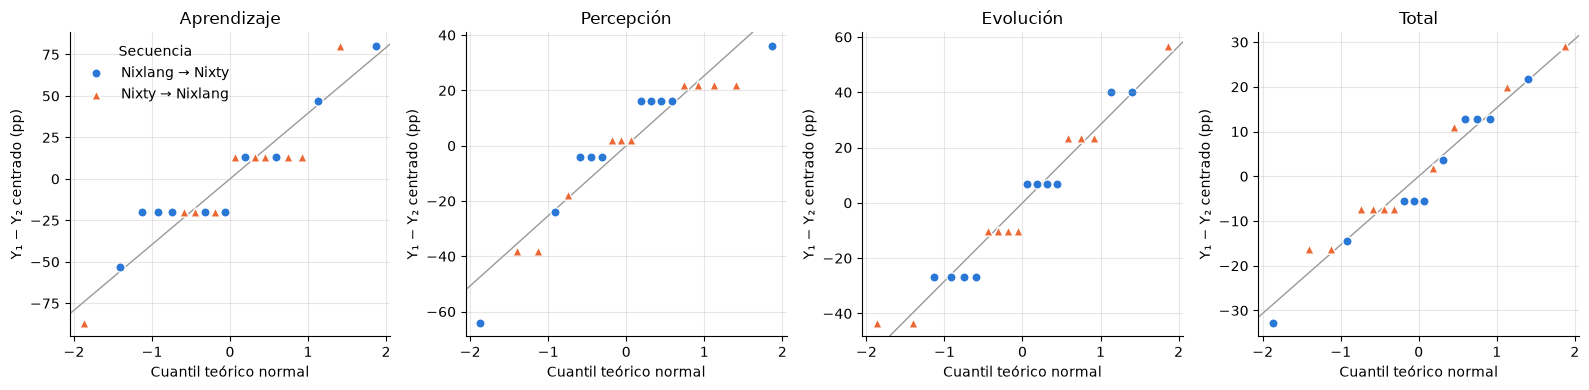

In [23]:
SEQUENCE_STYLE = {"Nixlang → Nixty": ("#2a78d6", "o"), "Nixty → Nixlang": ("#eb6834", "^")}

fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(4 * len(CATEGORIES), 4))
for ax, category in zip(axes, CATEGORIES):
    sample = residuals[category].sort_values()
    n = len(sample)
    theoretical = stats.norm.ppf((np.arange(1, n + 1) - 0.375) / (n + 0.25))  # Blom plotting positions
    ax.axline((0, 0), slope=sample.std(), color="0.6", linewidth=1, zorder=0)
    for sequence, (color, marker) in SEQUENCE_STYLE.items():
        in_sequence = sample.index.get_level_values("Secuencia") == sequence
        ax.scatter(
            theoretical[in_sequence], sample[in_sequence],
            color=color, marker=marker, s=45, edgecolor="white", linewidth=1, label=sequence,
        )
    ax.set(title=category, xlabel="Cuantil teórico normal", ylabel="Y₁ − Y₂ centrado (pp)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Secuencia", frameon=False)
fig.tight_layout()
plt.show()

Dado que 3 de las 4 comparaciones fallan la prueba de Shapiro-Wilk en alguno de los grupos y las graficas cuentan con poca resolución, no se determina normalidad, por lo que se procederá a hacer aplicar Mann-Witney-Wilkoxon

## Prueba estadística Mann-Witney-Wilkoxon

Prueba de Mann-Whitney sobre $d = Y_1 - Y_2$, comparando las dos secuencias en cada categoría
(Hills y Armitage, 1979; Koch, 1972). En *Nixty → Nixlang*, $d$ = Nixty − Nixlang + efecto de periodo;
en *Nixlang → Nixty*, $d$ = Nixlang − Nixty + el mismo efecto de periodo. Si las herramientas rinden
igual, los $d$ de ambas secuencias vienen de la misma distribución.

- H₀: $d$ tiene la misma distribución en las dos secuencias (Nixlang y Nixty tienen el mismo
  desempeño en la categoría).
- H₁: las distribuciones difieren (Nixlang y Nixty tienen distinto desempeño).
- Parámetros: bilateral, α = 0.05, n = 10 por secuencia. Como $d$ tiene muchos empates, p se calcula con
  la aproximación normal con corrección por empates y por continuidad (la prueba exacta de scipy no
  admite empates).

Columnas:

- `Mediana d … (pp)`: mediana de $d$ en cada secuencia.
- `Nixty − Nixlang estimada (pp)`: la mitad del estimador de Hodges-Lehmann, que es la mediana de las
  100 diferencias entre un $d$ de *Nixty → Nixlang* y uno de *Nixlang → Nixty*. Esa diferencia vale
  2 × (Nixty − Nixlang) porque el efecto de periodo se cancela. Positivo: Nixty tiene más aciertos.
- `IC 95% … (pp)`: intervalo de confianza de Moses para esa estimación. Se ordenan las 100 diferencias y
  se toman la $C$-ésima y la $(101 - C)$-ésima, con $C = n_1 n_2 / 2 - z_{0.975} \sqrt{n_1 n_2 (N + 1) / 12}$
  redondeado ($C = 24$ con 10 y 10, igual al valor de tabla), y se dividen entre 2. Si incluye 0, la
  diferencia no es significativa. Con tantos empates la cobertura es aproximada.
- `U`: estadístico de Mann-Whitney de la secuencia *Nixty → Nixlang*.
- `r biserial (−1–1)`: tamaño de efecto, $2U / (n_1 n_2) - 1$. Positivo favorece a Nixty; 0 es sin
  diferencia y ±1 que todos los $d$ de una secuencia superan a todos los de la otra.

In [24]:
TEST_CATEGORIES = ["Aprendizaje", "Percepción", "Evolución"]
NIXTY_FIRST, NIXLANG_FIRST = "Nixty → Nixlang", "Nixlang → Nixty"


def crossover_mann_whitney(d, unit="pp"):
    """Mann-Whitney of the period differences between sequences; positive effects favour Nixty."""
    nixty_first = d.xs(NIXTY_FIRST, level="Secuencia")
    nixlang_first = d.xs(NIXLANG_FIRST, level="Secuencia")
    u, p = stats.mannwhitneyu(nixty_first, nixlang_first, alternative="two-sided", method="asymptotic")
    pairwise = np.subtract.outer(nixty_first.to_numpy(), nixlang_first.to_numpy())
    # Moses confidence interval: the C-th smallest and largest of the sorted pairwise differences
    n1, n2 = len(nixty_first), len(nixlang_first)
    c = round(n1 * n2 / 2 - stats.norm.ppf(1 - ALPHA / 2) * np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12))
    ordered = np.sort(pairwise, axis=None)
    return pd.Series(
        {
            f"Mediana d {NIXLANG_FIRST} ({unit})": nixlang_first.median(),
            f"Mediana d {NIXTY_FIRST} ({unit})": nixty_first.median(),
            f"{DIFF} estimada ({unit})": np.median(pairwise) / 2,
            f"IC {1 - ALPHA:.0%} inferior ({unit})": ordered[c - 1] / 2,
            f"IC {1 - ALPHA:.0%} superior ({unit})": ordered[-c] / 2,
            "U": u,
            "r biserial (−1–1)": 2 * u / pairwise.size - 1,
            "p": p,
            f"Decisión (α = {ALPHA})": decision(p),
        }
    )


mann_whitney = pd.DataFrame({category: crossover_mann_whitney(d[category]) for category in TEST_CATEGORIES}).T
mann_whitney = mann_whitney.rename_axis("Categoría").infer_objects()
pp_columns = [column for column in mann_whitney.columns if column.endswith("(pp)")]
mann_whitney.round({**dict.fromkeys(pp_columns, 1), "U": 1, "r biserial (−1–1)": 2, "p": 3})

,Mediana d Nixlang → Nixty (pp),Mediana d Nixty → Nixlang (pp),Nixty − Nixlang estimada (pp),IC 95% inferior (pp),IC 95% superior (pp),U,r biserial (−1–1),p,Decisión (α = 0.05)
Categoría,,,,,,,,,
Aprendizaje,-33.3,0.0,0.0,-16.7,16.7,55.0,0.10,0.719,No se rechaza H₀
Percepción,-10.0,0.0,10.0,-10.0,20.0,65.5,0.31,0.240,No se rechaza H₀
Evolución,0.0,0.0,8.3,0.0,16.7,65.0,0.30,0.247,No se rechaza H₀


Las pruebas concluyen que Nixty no supuso ninguna diferencia entre la distribución de ambas secuencias, sin embargo r biserial muestra puntos puntos a favor the nixty indicando un campo positivo de la herramienta principalemnte en las areas de percepción y evolución, este se puede considerar un cambio medio a moderado segun Cohens.

## Dimensiones cognitivas

Utilizando la tabla de relaciones del inicio, cada pregunta se relaciono con diferentes dimensiones cognitivas en base a ellas se calcula el puntaje para cada dimension en nixty y Nixlang para cada participante, con la intención de aplicar Mann-Whitney wilkoxon para verificar si hay un diferencia entre las herramientas.

Puntaje de cada dimensión por participante y sesión con la fórmula del método,
$D_i = \sum_j Q_{ij} S_j / C_j$, donde $S_j$ es 1 si el participante acertó la pregunta $j$ en esa
sesión y 0 si no. El promedio de estos $D_i$ entre participantes es el $D_i$ calculado con la tasa de
éxito $S_j$ de todo el grupo. Para que sea fácil de leer y comparable entre dimensiones, cada $D_i$ se
expresa como porcentaje de su máximo, $\sum_j Q_{ij} / C_j$ (el puntaje con todas las preguntas
relacionadas correctas). Es solo un cambio de escala dentro de cada dimensión, así que no cambia las
pruebas.

La tabla tiene la misma forma que la de las categorías: una fila por participante, agrupada por
secuencia, y para cada dimensión $Y_1$ (%), $Y_2$ (%) y $Y_1 - Y_2$ (pp).

- *Evaluación progresiva* no se incluye: ninguna pregunta se relaciona con ella, así que su máximo es 0.
- *Cercanía de mapeo*, *Difusión* y *Propensión a errores* se relacionan con las 11 preguntas, y
  *Visibilidad* y *Gradiente de abstracción* con las mismas seis ($P_3$–$P_8$), así que tienen el mismo
  puntaje entre sí.
- *Notación secundaria* solo se relaciona con $P_8$: su puntaje es 0 % o 100 %.

In [25]:
DIMENSIONS = weights.index[weights.sum(axis=1) > 0].tolist()  # Evaluación progresiva has no question

# S_j = 1 when the participant answered question j correctly in that session
success = tasks.pivot_table(
    index=["Participante", "Posición"], columns="Pregunta", values="Acierto", aggfunc="mean"
)[weights.columns]
dimension_weights = weights.loc[DIMENSIONS]
dimension_scores = (
    success.dot(dimension_weights.T)  # D_i = sum_j Q_ij S_j / C_j
    .div(dimension_weights.sum(axis=1))  # as a share of the maximum D_i
    .mul(100)
    .unstack("Posición")
)

dimension_differences = period_table(dimension_scores, DIMENSIONS)
dimension_differences.round(1)

Cercanía de mapeo                     Viscosidad  \
                                        Y₁ (%) Y₂ (%) Y₁ − Y₂ (pp)     Y₁ (%)   
Secuencia       Participante                                                    
Nixlang → Nixty P05                       54.6   92.9        -38.3      100.0   
                P06                       35.6   68.0        -32.4      100.0   
                P08                       41.9   59.7        -17.7      100.0   
                P10                       83.4  100.0        -16.6       66.7   
                P12                       93.7   83.4         10.3      100.0   
                P14                       74.4   77.1         -2.7      100.0   
                P16                       76.3   63.3         13.0       66.7   
                P18                       56.2   74.4        -18.2      100.0   
                P20                       64.9   86.6        -21.7       66.7   
                P22                       41.5   40.3          1.1       33.3   
Nixty → Nixlang P02                       93.7   84.2          9.5      100.0   
                P03                       58.1   76.3        -18.2       66.7   
                P11                       58.1   70.7        -12.7       66.7   
                P13                       81.5  100.0        -18.5      100.0   
                P15                       69.9   41.9         28.0       66.7   
                P17                       93.7   67.6         26.1      100.0   
                P19                       46.7   68.8        -22.2       66.7   
                P21                       54.1   58.1         -4.0      100.0   
                P23                       62.5   84.2        -21.7      100.0   
                P24                       68.0   81.5        -13.4      100.0   

                                                 Dependencias ocultas         \
                             Y₂ (%) Y₁ − Y₂ (pp)               Y₁ (%) Y₂ (%)   
Secuencia       Participante                                                   
Nixlang → Nixty P05           100.0          0.0                 38.2  100.0   
                P06           100.0          0.0                 38.2   69.1   
                P08           100.0          0.0                 52.7   67.3   
                P10           100.0        -33.3                 83.6  100.0   
                P12            66.7         33.3                 85.5   83.6   
                P14            66.7         33.3                 67.3   85.5   
                P16           100.0        -33.3                 61.8   85.5   
                P18           100.0          0.0                 69.1   83.6   
                P20           100.0        -33.3                 67.3   69.1   
                P22            66.7        -33.3                 52.7   54.5   
Nixty → Nixlang P02            66.7         33.3                 85.5   85.5   
                P03            66.7          0.0                 69.1   67.3   
                P11            66.7          0.0                 69.1   54.5   
                P13           100.0          0.0                 83.6  100.0   
                P15           100.0        -33.3                 30.9   52.7   
                P17            33.3         66.7                 85.5   47.3   
                P19           100.0        -33.3                 69.1   54.5   
                P21            66.7         33.3                 54.5   69.1   
                P23            66.7         33.3                 83.6   85.5   
                P24           100.0          0.0                 52.7   83.6   

                                          Operaciones mentales difíciles  \
                             Y₁ − Y₂ (pp)                         Y₁ (%)   
Secuencia       Participante                                               
Nixlang → Nixty P05                 -61.8                           13.6   
                P06 

Prueba de Mann-Whitney sobre $d = Y_1 - Y_2$ de cada dimensión, comparando las dos secuencias, igual
que en las categorías.

- H₀: $d$ tiene la misma distribución en las dos secuencias (Nixlang y Nixty tienen el mismo
  desempeño en la dimensión).
- H₁: las distribuciones difieren (Nixlang y Nixty tienen distinto desempeño).
- Parámetros: bilateral, α = 0.05, n = 10 por secuencia, aproximación normal con corrección por
  empates y por continuidad.

Las dimensiones con la misma fila en la matriz $Q_{ij}$ tienen el mismo puntaje, así que se prueban
una sola vez y aparecen juntas en una fila (*Cercanía de mapeo / Difusión / Propensión a errores* y
*Visibilidad / Gradiente de abstracción*). Quedan 9 pruebas.

Las columnas son las de la tabla de las categorías, más `p Holm`: el valor p corregido por
comparaciones múltiples con el método de Holm (1979). Al hacer 9 pruebas, la probabilidad de que
alguna salga significativa por azar es mayor que α. Holm ordena los p de menor a mayor, multiplica el
$k$-ésimo por $(m - k + 1)$, con $m = 9$, y no deja que un p corregido sea menor que el anterior. Así
la probabilidad de algún falso positivo entre las 9 queda en α. La decisión usa `p Holm`.

In [26]:
def holm(p):
    """Holm-adjusted p-values, in the same order as p."""
    ordered = p.sort_values()
    m = len(p)
    adjusted = (ordered * np.arange(m, 0, -1)).cummax().clip(upper=1)
    return adjusted.reindex(p.index)


def add_holm(table):
    """Adds the Holm-adjusted p right after p and bases the decision on it."""
    table.insert(table.columns.get_loc("p") + 1, "p Holm", holm(table["p"]))
    table[f"Decisión (α = {ALPHA})"] = table["p Holm"].map(decision)
    return table


# Dimensions with the same row in Q_ij have the same score, so each distinct row is tested once
same_row = dimension_weights.groupby(list(dimension_weights.columns), sort=False).groups
TEST_DIMENSIONS = {" / ".join(dimensions): dimensions[0] for dimensions in same_row.values()}

dimension_d = dimension_differences.xs(D, axis=1, level=1)
dimension_mann_whitney = add_holm(
    pd.DataFrame(
        {label: crossover_mann_whitney(dimension_d[dimension]) for label, dimension in TEST_DIMENSIONS.items()}
    ).T.rename_axis("Dimensión").infer_objects()
)

pp_columns = [column for column in dimension_mann_whitney.columns if column.endswith("(pp)")]
dimension_mann_whitney.round({**dict.fromkeys(pp_columns, 1), "U": 1, "r biserial (−1–1)": 2, "p": 3, "p Holm": 3})

,Mediana d Nixlang → Nixty (pp),Mediana d Nixty → Nixlang (pp),Nixty − Nixlang estimada (pp),IC 95% inferior (pp),IC 95% superior (pp),U,r biserial (−1–1),p,p Holm,Decisión (α = 0.05)
Dimensión,,,,,,,,,,
Cercanía de mapeo / Difusión / Propensión a errores,-17.2,-13.1,2.5,-6.9,12.8,57.0,0.14,0.623,1.000,No se rechaza H₀
Viscosidad,0.0,0.0,8.3,0.0,16.7,65.0,0.30,0.247,1.000,No se rechaza H₀
Dependencias ocultas,-15.5,-0.9,7.3,-0.9,16.4,71.5,0.43,0.111,0.997,No se rechaza H₀
Operaciones mentales difíciles,-18.4,0.8,5.3,-4.8,17.6,60.0,0.20,0.470,1.000,No se rechaza H₀
Anticipación impuesta,0.0,0.0,0.0,0.0,25.0,65.0,0.30,0.232,1.000,No se rechaza H₀
Notación secundaria,0.0,0.0,0.0,0.0,50.0,66.0,0.32,0.182,1.000,No se rechaza H₀
Visibilidad / Gradiente de abstracción,-8.7,1.0,7.7,-1.0,16.3,70.0,0.40,0.137,1.000,No se rechaza H₀
Consistencia,0.0,0.0,0.0,-23.5,2.9,43.0,-0.14,0.605,1.000,No se rechaza H₀
Expresividad de rol,-12.0,-1.2,6.5,-0.8,15.3,69.5,0.39,0.150,1.000,No se rechaza H₀


# Usabilidad

## Experiencia de Usuario General OUX

Antes de los pares de palabras, cada cuestionario de valoración tuvo dos preguntas de un solo ítem
(escala 1–7), tomadas de Kuusinen (2016): OUX y NFS (sección siguiente). OUX es la evaluación general
de la experiencia de usuario: *¿Cómo calificarías la experiencia de usuario de {tool}?*, de *Malo* a
*Bueno*. Se mostró con *Bueno* a la izquierda, así que se recodifica como $8 - x$ y 7 es *Bueno*.

La tabla tiene la misma forma que las anteriores: una fila por participante, agrupada por secuencia, con
$Y_1$ y $Y_2$ en la escala 1–7 y $Y_1 - Y_2$ en puntos de esa escala.

In [27]:
D_UX = "Y₁ − Y₂ (puntos)"

# OUX and NFS, one row per participant, tool and question, recoded so 7 = positive pole.
# Both are one-item likerts, so the item is named after the question ("experience", "needs")
global_ratings = raw_phase3[raw_phase3["question_id"].str.endswith((".feedback.experience", ".feedback.needs"))]
global_ratings = global_ratings.assign(item=global_ratings["question_id"].str.rsplit(".", n=1).str[-1]).join(ux_items, on="item")
global_ratings = pd.DataFrame(
    {
        "Participante": global_ratings["username"],
        "Herramienta": global_ratings["step"].map(TOOLS),
        "Posición": global_ratings["step_position"].map({1: "Primera", 2: "Segunda"}),
        "Instrumento": global_ratings["Instrumento"],
        "Valor (1–7)": np.where(global_ratings["Invertido"], 8 - global_ratings["value"].astype(int), global_ratings["value"].astype(int)),
    }
).reset_index(drop=True)
assert (global_ratings.groupby(["Participante", "Herramienta"]).size() == 2).all()


def single_item_differences(instrument):
    """Y₁, Y₂ and Y₁ − Y₂ of a one-item instrument (OUX or NFS)."""
    scores = global_ratings.pivot_table(index="Participante", columns=["Instrumento", "Posición"], values="Valor (1–7)")
    return period_table(scores, [instrument], unit="1–7", diff_unit="puntos")


oux_differences = single_item_differences("OUX")
oux_differences.round(2)

OUX                          
                             Y₁ (1–7) Y₂ (1–7) Y₁ − Y₂ (puntos)
Secuencia       Participante                                   
Nixlang → Nixty P05               7.0      7.0              0.0
                P06               4.0      7.0             -3.0
                P08               6.0      7.0             -1.0
                P10               3.0      6.0             -3.0
                P12               6.0      5.0              1.0
                P14               3.0      6.0             -3.0
                P16               6.0      6.0              0.0
                P18               5.0      7.0             -2.0
                P20               2.0      6.0             -4.0
                P22               5.0      6.0             -1.0
Nixty → Nixlang P02               6.0      2.0              4.0
                P03               4.0      2.0              2.0
                P11               4.0      4.0              0.0
                P13               7.0      7.0              0.0
                P15               2.0      5.0             -3.0
                P17               7.0      3.0              4.0
                P19               6.0      3.0              3.0
                P21               5.0      2.0              3.0
                P23               6.0      7.0             -1.0
                P24               7.0      7.0              0.0

Prueba de Mann-Whitney sobre $d = Y_1 - Y_2$ de OUX, comparando las dos secuencias, igual que en las
categorías.

- H₀: $d$ tiene la misma distribución en las dos secuencias (Nixlang y Nixty reciben la misma
  valoración general).
- H₁: las distribuciones difieren (Nixlang y Nixty reciben distinta valoración general).
- Parámetros: bilateral, α = 0.05, n = 10 por secuencia, aproximación normal con corrección por
  empates y por continuidad. Es una sola prueba, así que no lleva corrección de Holm (en SAD-2 y DEXI
  Holm se aplica dentro de cada instrumento).

`Promedio Nixlang` y `Promedio Nixty` son la valoración promedio de los 20 participantes a cada
herramienta (descriptivos, no separan el efecto de la sesión). Al ser un solo ítem de 7 valores hay
muchos empates.

El signo de `Nixty − Nixlang estimada` y de `r biserial` solo indica la dirección: positivo si Nixty
recibe mejor valoración, negativo si la recibe Nixlang. Si la diferencia es significativa lo dice la
columna `Decisión`.

In [28]:
def round_ux(table):
    """Rounds a UX test table: scale points to 2 decimals and p to 3."""
    points = [column for column in table.columns if column.endswith(("(puntos)", "(1–7)"))]
    return table.round({**dict.fromkeys(points, 2), "U": 1, "r biserial (−1–1)": 2, "p": 3, "p Holm": 3})


def single_item_mann_whitney(differences):
    """Each tool's average and the crossover Mann-Whitney of a one-item instrument."""
    instrument = differences.columns.get_level_values(0)[0]
    tool_means = global_ratings[global_ratings["Instrumento"] == instrument].groupby("Herramienta")["Valor (1–7)"].mean()
    row = pd.concat(
        [
            tool_means[TOOL_ORDER].add_prefix("Promedio ").add_suffix(" (1–7)"),
            crossover_mann_whitney(differences[(instrument, D_UX)], unit="puntos"),
        ]
    )
    return row.to_frame(instrument).T.rename_axis("Instrumento").infer_objects()


oux_mann_whitney = single_item_mann_whitney(oux_differences)
round_ux(oux_mann_whitney)

,Promedio Nixlang (1–7),Promedio Nixty (1–7),Mediana d Nixlang → Nixty (puntos),Mediana d Nixty → Nixlang (puntos),Nixty − Nixlang estimada (puntos),IC 95% inferior (puntos),IC 95% superior (puntos),U,r biserial (−1–1),p,Decisión (α = 0.05)
Instrumento,,,,,,,,,,,
OUX,4.45,5.85,-1.5,1.0,1.5,0.5,2.5,82.5,0.65,0.014,Se rechaza H₀


##  NFS

NFS es la capacidad de la herramienta para responder a las necesidades del participante: *¿Qué tan bien
{tool} respondió a tus necesidades?*, de *Para nada* (1) a *Completamente* (7). Ya tiene el polo positivo
a la derecha, así que no se recodifica. La tabla tiene la misma forma que la de OUX.

In [29]:
nfs_differences = single_item_differences("NFS")
nfs_differences.round(2)

NFS                          
                             Y₁ (1–7) Y₂ (1–7) Y₁ − Y₂ (puntos)
Secuencia       Participante                                   
Nixlang → Nixty P05               1.0      7.0             -6.0
                P06               4.0      5.0             -1.0
                P08               6.0      7.0             -1.0
                P10               6.0      2.0              4.0
                P12               7.0      6.0              1.0
                P14               5.0      5.0              0.0
                P16               4.0      6.0             -2.0
                P18               5.0      7.0             -2.0
                P20               6.0      5.0              1.0
                P22               6.0      5.0              1.0
Nixty → Nixlang P02               2.0      3.0             -1.0
                P03               2.0      2.0              0.0
                P11               3.0      4.0             -1.0
                P13               7.0      7.0              0.0
                P15               6.0      5.0              1.0
                P17               7.0      6.0              1.0
                P19               4.0      4.0              0.0
                P21               4.0      4.0              0.0
                P23               6.0      6.0              0.0
                P24               6.0      6.0              0.0

Prueba de Mann-Whitney sobre $d = Y_1 - Y_2$ de NFS, igual que la de OUX.

- H₀: $d$ tiene la misma distribución en las dos secuencias (Nixlang y Nixty responden igual de bien a
  las necesidades del participante).
- H₁: las distribuciones difieren (una herramienta responde mejor a las necesidades que la otra).
- Parámetros: bilateral, α = 0.05, n = 10 por secuencia, aproximación normal con corrección por
  empates y por continuidad, sin corrección de Holm (una sola prueba).

Las columnas son las de la tabla de OUX.

El signo de `Nixty − Nixlang estimada` y de `r biserial` solo indica la dirección: positivo si Nixty
recibe mejor valoración, negativo si la recibe Nixlang. Si la diferencia es significativa lo dice la
columna `Decisión`.

In [30]:
nfs_mann_whitney = single_item_mann_whitney(nfs_differences)
round_ux(nfs_mann_whitney)

,Promedio Nixlang (1–7),Promedio Nixty (1–7),Mediana d Nixlang → Nixty (puntos),Mediana d Nixty → Nixlang (puntos),Nixty − Nixlang estimada (puntos),IC 95% inferior (puntos),IC 95% superior (puntos),U,r biserial (−1–1),p,Decisión (α = 0.05)
Instrumento,,,,,,,,,,,
NFS,4.85,5.1,-0.5,0.0,0.0,-0.5,1.0,56.0,0.12,0.667,No se rechaza H₀


## Short AttrakDiff 2 (SAD-2)

Al terminar cada cuestionario, el participante calificó la herramienta con los 22 pares de palabras
(escala 1–7); los 10 primeros son SAD-2. Los ítems `Invertido` (el polo positivo estaba a la
izquierda) se recodifican como $8 - x$, así que en todos los ítems 7 es el polo positivo. El puntaje de
cada calidad es el promedio de sus ítems: *General* 2 ítems, *Pragmática* 4 y *Hedónica* 4.

La tabla tiene la misma forma que las anteriores: una fila por participante, agrupada por secuencia, y
para cada calidad $Y_1$ y $Y_2$ en la escala 1–7 y $Y_1 - Y_2$ en puntos de esa escala.

In [31]:
QUALITIES = ["General", "Pragmática", "Hedónica"]

# Word pairs (SAD-2 and DEXI), one row per participant, tool and item, recoded so 7 = positive pole
word_pairs = raw_phase3[raw_phase3["question_id"].str.endswith(".feedback.word-pairs")].join(ux_items, on="item_id")
word_pairs = pd.DataFrame(
    {
        "Participante": word_pairs["username"],
        "Herramienta": word_pairs["step"].map(TOOLS),
        "Posición": word_pairs["step_position"].map({1: "Primera", 2: "Segunda"}),
        "Ítem": word_pairs["item_id"],
        "Instrumento": word_pairs["Instrumento"],
        "Calidad": word_pairs["Calidad"],
        "Valor (1–7)": np.where(word_pairs["Invertido"], 8 - word_pairs["value"].astype(int), word_pairs["value"].astype(int)),
    }
).reset_index(drop=True)
assert (word_pairs.groupby(["Participante", "Herramienta"]).size() == len(ux_items) - 2).all()



def quality_differences(instrument):
    """Y₁, Y₂ and Y₁ − Y₂ of each quality of an instrument, scored as the mean of its items."""
    scores = word_pairs[word_pairs["Instrumento"] == instrument].pivot_table(
        index="Participante", columns=["Calidad", "Posición"], values="Valor (1–7)", aggfunc="mean"
    )
    return period_table(scores, QUALITIES, unit="1–7", diff_unit="puntos")


sad2_differences = quality_differences("SAD-2")
sad2_differences.round(2)

General                           Pragmática  \
                             Y₁ (1–7) Y₂ (1–7) Y₁ − Y₂ (puntos)   Y₁ (1–7)   
Secuencia       Participante                                                 
Nixlang → Nixty P05               6.5      6.5              0.0       6.25   
                P06               4.0      6.5             -2.5       6.25   
                P08               6.5      7.0             -0.5       5.00   
                P10               6.0      6.0              0.0       2.50   
                P12               5.5      6.0             -0.5       4.75   
                P14               5.0      5.0              0.0       4.25   
                P16               4.5      5.5             -1.0       4.50   
                P18               4.0      6.0             -2.0       5.00   
                P20               4.5      6.0             -1.5       4.50   
                P22               6.0      5.0              1.0       4.25   
Nixty → Nixlang P02               6.0      2.0              4.0       4.75   
                P03               4.5      2.5              2.0       4.50   
                P11               4.0      4.5             -0.5       3.25   
                P13               7.0      7.0              0.0       4.00   
                P15               6.0      4.5              1.5       5.25   
                P17               7.0      3.5              3.5       6.50   
                P19               6.5      3.0              3.5       4.00   
                P21               5.0      3.0              2.0       4.50   
                P23               5.5      6.0             -0.5       6.00   
                P24               7.0      5.5              1.5       5.50   

                                                       Hedónica           \
                             Y₂ (1–7) Y₁ − Y₂ (puntos) Y₁ (1–7) Y₂ (1–7)   
Secuencia       Participante                                               
Nixlang → Nixty P05              7.00            -0.75     6.00     6.25   
                P06              6.25             0.00     4.00     4.25   
                P08              5.25            -0.25     6.00     4.00   
                P10              4.00            -1.50     4.25     4.00   
                P12              4.25             0.50     5.25     4.25   
                P14              5.25            -1.00     3.75     4.25   
                P16              5.75            -1.25     2.75     3.50   
                P18              6.25            -1.25     3.75     5.00   
                P20              5.00            -0.50     4.00     4.50   
                P22              6.25            -2.00     4.75     4.50   
Nixty → Nixlang P02              2.25             2.50     4.25     3.75   
                P03              1.25             3.25     3.50     3.50   
                P11              4.50            -1.25     4.25     4.25   
                P13              6.00            -2.00     6.25     7.00   
                P15              4.00             1.25     6.00     4.00   
                P17              1.75             4.75     6.25     1.75   
                P19              3.75             0.25     5.25     3.75   
                P21              2.75             1.75     3.50     4.00   
                P23              6.25            -0.25     6.75     6.25   
                P24              5.75            -0.25     5.75     5.00   

                                               
                             Y₁ − Y₂ (puntos)  
Secuencia       Participante                   
Nixlang → Nixty P05                     -0.25  
                P06                     -0.25  
                P08                      2.00  
                P10                      0.25  
                P12                      1.00  
                P14                     -0.50  
                P16                     -0.75  
      

Prueba de Mann-Whitney sobre $d = Y_1 - Y_2$ de cada calidad de SAD-2, comparando las dos
secuencias, igual que en las categorías y las dimensiones.

- H₀: $d$ tiene la misma distribución en las dos secuencias (Nixlang y Nixty reciben la misma
  valoración en la calidad).
- H₁: las distribuciones difieren (Nixlang y Nixty reciben distinta valoración).
- Parámetros: bilateral, α = 0.05, n = 10 por secuencia, aproximación normal con corrección por
  empates y por continuidad. Holm sobre las 3 calidades ($m = 3$); la decisión usa `p Holm`.

Las columnas son las de las tablas anteriores, en puntos de la escala 1–7 en lugar de pp.

El signo de `Nixty − Nixlang estimada` y de `r biserial` solo indica la dirección: positivo si Nixty
recibe mejor valoración, negativo si la recibe Nixlang. Si la diferencia es significativa lo dice la
columna `Decisión`.

In [32]:
def quality_mann_whitney(differences):
    """Crossover Mann-Whitney of each quality, with Holm over the qualities."""
    d = differences.xs(D_UX, axis=1, level=1)
    return add_holm(
        pd.DataFrame({quality: crossover_mann_whitney(d[quality], unit="puntos") for quality in QUALITIES})
        .T.rename_axis("Calidad")
        .infer_objects()
    )


sad2_mann_whitney = quality_mann_whitney(sad2_differences)
round_ux(sad2_mann_whitney)

,Mediana d Nixlang → Nixty (puntos),Mediana d Nixty → Nixlang (puntos),Nixty − Nixlang estimada (puntos),IC 95% inferior (puntos),IC 95% superior (puntos),U,r biserial (−1–1),p,p Holm,Decisión (α = 0.05)
Calidad,,,,,,,,,,
General,-0.50,1.75,1.25,0.50,2.00,87.5,0.75,0.005,0.014,Se rechaza H₀
Pragmática,-0.88,0.75,0.81,0.00,1.75,77.5,0.55,0.041,0.081,No se rechaza H₀
Hedónica,-0.25,0.50,0.31,-0.12,0.88,69.0,0.38,0.160,0.160,No se rechaza H₀


Detalle por par de palabras de SAD-2, en el orden en que se mostraron. `Promedio Nixlang` y
`Promedio Nixty` son la valoración promedio de los 20 participantes a cada herramienta (escala 1–7, ya
recodificada: 7 es el polo positivo, a la derecha del par). Son descriptivos y no separan el efecto de
la sesión.

El resto de las columnas es la misma prueba de Mann-Whitney sobre $d = Y_1 - Y_2$ entre secuencias,
aplicada a cada par por separado, con H₀, H₁ y parámetros iguales a los de las calidades. Holm se
aplica sobre los 10 pares ($m = 10$) y la decisión usa `p Holm`. Es un análisis exploratorio para
ver qué pares explican la diferencia de cada calidad; con un solo ítem de 7 valores hay muchos
empates.

In [33]:
def word_pair_table(instrument):
    """Each tool's average and the crossover Mann-Whitney of every word pair, with Holm over the pairs."""
    items = ux_items[ux_items["Instrumento"] == instrument]
    pairs = word_pairs[word_pairs["Instrumento"] == instrument]
    item_scores = pairs.pivot_table(index="Participante", columns=["Ítem", "Posición"], values="Valor (1–7)")
    item_d = period_table(item_scores, items.index, unit="1–7", diff_unit="puntos").xs(D_UX, axis=1, level=1)
    tool_means = pairs.groupby(["Ítem", "Herramienta"])["Valor (1–7)"].mean().unstack()[TOOL_ORDER]
    tests = add_holm(
        pd.DataFrame({item: crossover_mann_whitney(item_d[item], unit="puntos") for item in items.index}).T.infer_objects()
    )
    return (
        items[["Calidad", "Par (negativo – positivo)"]]
        .join(tool_means.add_prefix("Promedio ").add_suffix(" (1–7)"))
        .join(tests)
        .set_index(["Calidad", "Par (negativo – positivo)"])
    )


sad2_word_pair_table = word_pair_table("SAD-2")
round_ux(sad2_word_pair_table)

Promedio Nixlang (1–7)  \
Calidad    Par (negativo – positivo)                           
General    Malo – Bueno                                 5.00   
           Feo – Bonito                                 4.40   
Pragmática Confuso – Estructurado                       4.35   
           Impráctico – Práctico                        4.20   
           Impredecible – Predecible                    4.85   
           Complicado – Simple                          3.70   
Hedónica   Antipático – Cautivador                      4.10   
           Tosco – Elegante                             4.60   
           Barato – Prémium                             4.35   
           No imaginativo – Creativo                    4.50   

                                      Promedio Nixty (1–7)  \
Calidad    Par (negativo – positivo)                         
General    Malo – Bueno                               5.95   
           Feo – Bonito                               5.85   
Pragmática Confuso – Estructurado                     5.60   
           Impráctico – Práctico                      4.50   
           Impredecible – Predecible                  5.85   
           Complicado – Simple                        4.75   
Hedónica   Antipático – Cautivador                    4.95   
           Tosco – Elegante                           5.25   
           Barato – Prémium                           4.40   
           No imaginativo – Creativo                  4.65   

                                      Mediana d Nixlang → Nixty (puntos)  \
Calidad    Par (negativo – positivo)                                       
General    Malo – Bueno                                             -0.5   
           Feo – Bonito                                             -1.0   
Pragmática Confuso – Estructurado                                    0.0   
           Impráctico – Práctico                                    -0.5   
           Impredecible – Predecible                                -1.0   
           Complicado – Simple                                      -1.5   
Hedónica   Antipático – Cautivador                                  -0.5   
           Tosco – Elegante                                          0.5   
           Barato – Prémium                                          0.0   
           No imaginativo – Creativo                                 0.0   

                                      Mediana d Nixty → Nixlang (puntos)  \
Calidad    Par (negativo – positivo)                                       
General    Malo – Bueno                                              1.0   
           Feo – Bonito                                              2.0   
Pragmática Confuso – Estructurado                                    2.0   
           Impráctico – Práctico                                     0.0   
           Impredecible – Predecible                                 1.0   
           Complicado – Simple                                       1.0   
Hedónica   Antipático – Cautivador                                   1.5   
           Tosco – Elegante                                          1.0   
           Barato – Prémium                                          0.0   
           No imaginativo – Creativo                                 0.0   

                                      Nixty − Nixlang estimada (puntos)  \
Calidad    Par (negativo – positivo)                                      
General    Malo – Bueno                                            1.00   
           Feo – Bonito                                            1.50   
Pragmática Confuso – Estructurado                                  1.00   
           Impráctico – Práctico                                   0.25   
           Impredecible – Predecible                               1.00   
           Complicado – Simple                                     1.00   
Hedónica   Antipático – Cautivador                                 1.00   
           Tosco – Eleg

## DEXI

Los 12 pares de palabras restantes son DEXI, con la misma escala, recodificación y puntaje por
calidad que SAD-2: *General* tiene un solo ítem (*No recomendable – Recomendable*), *Pragmática* 5 y
*Hedónica* 6.

La tabla tiene la misma forma que la de SAD-2: una fila por participante, agrupada por secuencia, y
para cada calidad $Y_1$ y $Y_2$ en la escala 1–7 y $Y_1 - Y_2$ en puntos de esa escala.

In [34]:
dexi_differences = quality_differences("DEXI")
dexi_differences.round(2)

General                           Pragmática  \
                             Y₁ (1–7) Y₂ (1–7) Y₁ − Y₂ (puntos)   Y₁ (1–7)   
Secuencia       Participante                                                 
Nixlang → Nixty P05               7.0      6.0              1.0        6.4   
                P06               4.0      7.0             -3.0        3.8   
                P08               7.0      6.0              1.0        5.0   
                P10               3.0      7.0             -4.0        4.0   
                P12               6.0      5.0              1.0        5.4   
                P14               5.0      5.0              0.0        3.4   
                P16               5.0      6.0             -1.0        3.0   
                P18               4.0      6.0             -2.0        5.2   
                P20               6.0      6.0              0.0        4.6   
                P22               5.0      5.0              0.0        4.6   
Nixty → Nixlang P02               7.0      2.0              5.0        6.2   
                P03               7.0      1.0              6.0        3.6   
                P11               4.0      5.0             -1.0        4.0   
                P13               7.0      7.0              0.0        5.8   
                P15               7.0      5.0              2.0        5.2   
                P17               7.0      1.0              6.0        6.8   
                P19               4.0      1.0              3.0        3.8   
                P21               4.0      4.0              0.0        4.6   
                P23               7.0      7.0              0.0        5.6   
                P24               7.0      6.0              1.0        6.4   

                                                       Hedónica           \
                             Y₂ (1–7) Y₁ − Y₂ (puntos) Y₁ (1–7) Y₂ (1–7)   
Secuencia       Participante                                               
Nixlang → Nixty P05               6.2              0.2     6.67     6.67   
                P06               4.6             -0.8     5.33     4.00   
                P08               6.0             -1.0     6.17     6.83   
                P10               5.0             -1.0     3.83     4.33   
                P12               5.4              0.0     6.33     4.50   
                P14               4.6             -1.2     3.50     4.67   
                P16               5.0             -2.0     4.00     5.33   
                P18               6.2             -1.0     4.17     5.83   
                P20               6.2             -1.6     4.17     4.83   
                P22               4.4              0.2     5.00     5.00   
Nixty → Nixlang P02               3.4              2.8     5.00     2.50   
                P03               3.4              0.2     3.00     3.17   
                P11               4.2             -0.2     4.17     4.50   
                P13               6.4             -0.6     6.83     7.00   
                P15               4.8              0.4     6.17     5.67   
                P17               3.4              3.4     5.50     2.50   
                P19               4.2             -0.4     5.50     3.67   
                P21               4.0              0.6     3.50     3.67   
                P23               5.6              0.0     6.67     6.83   
                P24               5.6              0.8     6.50     5.33   

                                               
                             Y₁ − Y₂ (puntos)  
Secuencia       Participante                   
Nixlang → Nixty P05                      0.00  
                P06                      1.33  
                P08                     -0.67  
                P10                     -0.50  
                P12                      1.83  
                P14                     -1.17  
                P16                     -1.33  
      

Prueba de Mann-Whitney sobre $d = Y_1 - Y_2$ de cada calidad de DEXI, comparando las dos secuencias,
igual que en SAD-2.

- H₀: $d$ tiene la misma distribución en las dos secuencias (Nixlang y Nixty reciben la misma
  valoración en la calidad).
- H₁: las distribuciones difieren (Nixlang y Nixty reciben distinta valoración).
- Parámetros: bilateral, α = 0.05, n = 10 por secuencia, aproximación normal con corrección por
  empates y por continuidad. Holm sobre las 3 calidades ($m = 3$); la decisión usa `p Holm`.

Como *General* tiene un solo ítem, su $d$ es el de *Recomendable* y su p sin corregir es el mismo de
ese par en la tabla siguiente.

El signo de `Nixty − Nixlang estimada` y de `r biserial` solo indica la dirección: positivo si Nixty
recibe mejor valoración, negativo si la recibe Nixlang. Si la diferencia es significativa lo dice la
columna `Decisión`.

In [35]:
dexi_mann_whitney = quality_mann_whitney(dexi_differences)
round_ux(dexi_mann_whitney)

,Mediana d Nixlang → Nixty (puntos),Mediana d Nixty → Nixlang (puntos),Nixty − Nixlang estimada (puntos),IC 95% inferior (puntos),IC 95% superior (puntos),U,r biserial (−1–1),p,p Holm,Decisión (α = 0.05)
Calidad,,,,,,,,,,
General,0.00,1.50,1.5,0.00,2.50,78.5,0.57,0.031,0.062,No se rechaza H₀
Pragmática,-1.00,0.30,0.6,0.20,1.20,87.5,0.75,0.005,0.015,Se rechaza H₀
Hedónica,-0.58,0.17,0.5,-0.08,1.17,75.5,0.51,0.058,0.062,No se rechaza H₀


Detalle por par de palabras de DEXI, igual que el de SAD-2: el promedio de cada herramienta
(descriptivo, 7 es el polo positivo) y la prueba de Mann-Whitney entre secuencias para cada par. Holm
se aplica sobre los 12 pares ($m = 12$) y la decisión usa `p Holm`. Es un análisis exploratorio.

In [36]:
dexi_word_pair_table = word_pair_table("DEXI")
round_ux(dexi_word_pair_table)

Promedio Nixlang (1–7)  \
Calidad    Par (negativo – positivo)                                                  
General    No recomendable – Recomendable                                      4.55   
Pragmática Ineficiente – Eficiente                                             5.55   
           Rígido – Flexible                                                   4.55   
           Difícil de aprender – Fácil de aprender                             3.25   
           Limitado – Extensivo                                                4.60   
           Desinformativo – Informativo                                        4.65   
Hedónica   Desmotivador – Motivador                                            4.00   
           Genera desconfianza – Genera respeto                                5.50   
           Desagradable – Agradable                                            4.75   
           Suprime la creatividad – Promueve la creatividad                    4.90   
           Aburrido – Envolvente                                               4.10   
           Me aleja de otros – Me acerca a otros                               4.95   

                                                             Promedio Nixty (1–7)  \
Calidad    Par (negativo – positivo)                                                
General    No recomendable – Recomendable                                    6.00   
Pragmática Ineficiente – Eficiente                                           5.55   
           Rígido – Flexible                                                 5.15   
           Difícil de aprender – Fácil de aprender                           5.40   
           Limitado – Extensivo                                              5.15   
           Desinformativo – Informativo                                      5.15   
Hedónica   Desmotivador – Motivador                                          5.30   
           Genera desconfianza – Genera respeto                              5.15   
           Desagradable – Agradable                                          5.60   
           Suprime la creatividad – Promueve la creatividad                  5.30   
           Aburrido – Envolvente                                             4.90   
           Me aleja de otros – Me acerca a otros                             5.20   

                                                             Mediana d Nixlang → Nixty (puntos)  \
Calidad    Par (negativo – positivo)                                                              
General    No recomendable – Recomendable                                                   0.0   
Pragmática Ineficiente – Eficiente                                                          0.0   
           Rígido – Flexible                                                                0.0   
           Difícil de aprender – Fácil de aprender                                         -2.5   
           Limitado – Extensivo                                                            -1.0   
           Desinformativo – Informativo                                                     0.0   
Hedónica   Desmotivador – Motivador                                                        -1.0   
           Genera desconfianza – Genera respeto                                             0.0   
           Desagradable – Agradable                                                        -0.5   
           Suprime la creatividad – Promueve la creatividad                                -0.5   
           Aburrido – Envolvente                                                           -0.5   
           Me aleja de otros – Me acerca a otros                                            0.0   

                                                             Mediana d Nixty → Nixlang (puntos)  \
Calidad    Par (negativo – positivo)                                                              
General    No recomendable – Recomendable                         

# OPINIONES

Comentarios libres que dejó cada participante al final de cada cuestionario (pregunta opcional
*¿Algún comentario adicional que quieras destacar sobre tu experiencia usando {tool}?*), sin editar.
Solo se incluyen los que escribieron algo.

Una fila por comentario, agrupada por secuencia y participante. `Herramienta` es la herramienta que
estaba calificando y `Sesión` si fue su primer o segundo cuestionario.

In [37]:
comments = raw_phase3[raw_phase3["question_id"].str.endswith(".feedback.comments")]
comments = pd.DataFrame(
    {
        "Secuencia": comments["survey_order"].map(ORDERS),
        "Participante": comments["username"],
        "Sesión": comments["step_position"].map({1: "Primera", 2: "Segunda"}),
        "Herramienta": comments["step"].map(TOOLS),
        "Comentario": comments["value"].str.strip(),
    }
)
answered = comments["Comentario"].fillna("") != ""
print(f"{answered.sum()} comentarios de {comments.loc[answered, 'Participante'].nunique()} participantes "
      f"({len(comments)} cuestionarios, {(~answered).sum()} sin comentario)")

comments = comments[answered].sort_values(["Secuencia", "Participante", "Sesión"]).set_index(["Secuencia", "Participante"])
with pd.option_context("display.max_colwidth", None):  # full comments, not truncated
    display(comments)

11 comentarios de 7 participantes (40 cuestionarios, 29 sin comentario)


Sesión Herramienta  \
Secuencia       Participante                        
Nixlang → Nixty P05           Primera     Nixlang   
                P20           Primera     Nixlang   
                P20           Segunda       Nixty   
Nixty → Nixlang P02           Primera       Nixty   
                P02           Segunda     Nixlang   
                P13           Primera       Nixty   
                P13           Segunda     Nixlang   
                P15           Primera       Nixty   
                P15           Segunda     Nixlang   
                P17           Segunda     Nixlang   
                P24           Primera       Nixty   

                                                                                                                                                                                                    Comentario  
Secuencia       Participante                                                                                                                                                                                    
Nixlang → Nixty P05                                                                                                                                      Para nunca haber usado Nix fue muy intuitivo de usar.  
                P20                            En general fue una buena experiencia. Aprendí mucho y si siento que esta pensado para un objetivo especifico, que es poder manejar y crear los paquetes de Nix.  
                P20                                                                                                                      Me pareció una muy buena experiencia. Mucho más intuitivo que NixLang  
Nixty → Nixlang P02                                                                                                     Bastante más sencillo encontrar y resolver errores de lo que fue en la primera prueba.  
                P02                                                   Algunas cosas fueron más fáciles de resolver (a comparación de si hubiera hecho esto primero) porque Nixty me dio un poco más de lógica.  
                P13           Me gustó poder definir paquetes y devshells con sintaxis de TypeScript, aunque al principio me costó entender algunas funciones como getDerivation y cómo se pasan los sistemas.  
                P13                 La sintaxis de Nix me resultó menos intuitiva que la de Nixty, sobre todo los ;, el let ... in y el uso de genAttrs, aunque la evaluación perezosa me pareció interesante.  
                P15                                                                                                                       siento raro que se tiene que colocar una comas para las definiicones  
                P15                                                                        pedue ser algo dificíl al comenzar o interpretar pero al tomar al leer detallada la documentación se puede entender  
                P17                                                                                                        No me gustó; honestamente, no lo volvería a usar. Preferiría usar otra alternativa.  
                P24                                                                         Me parece bastante estructurado y facil de entender si se lee bien la documentación y se tiene experiencia previa.